In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
#Loading in data
#Check for missing values is in looking_at_data_options.ipynb


living_cases_url = 'https://virginia.box.com/shared/static/hfkttdmmyd4dg3sh7qumusevxxduimyq.csv'
living_cases = pd.read_csv(living_cases_url)
new_cases_url = 'https://virginia.box.com/shared/static/zjmyugj5gh68e5kuw2a923w1r2t55l0s.csv'
new_cases = pd.read_csv(new_cases_url)
deaths_url = 'https://virginia.box.com/shared/static/cssyj0b90kbzjesyfjfd08ohrownn0uj.csv'
deaths = pd.read_csv(deaths_url)

# Combine the CSVs without error
# Solution provided by Prof. Alvarado

'''It turns out that each table had two different category names, corresponding to their unit of observation.
So, [Prof. Alvarado] just changed them, but the user should know what 'Age' and 'City' actually mean when viewing results.'''

key = ['Year', 'Category', 'Group']

df1 = living_cases.rename(columns={'Count': 'Count_Living'})
df1['Category'] = df1['Category'].replace({'Age at Year End (in years)':'Age', 'City of Current Residence':'City', 'County of Current Residence':'County'})
df1 = df1.set_index(key)

df2 = new_cases.rename(columns={'Count': 'Count_New'})
df2['Category'] = df2['Category'].replace({'Age at Diagnosis (in years)':'Age', 'City of Residence at Diagnosis':'City', 'County of Residence at Diagnosis':'County'})
df2 = df2.set_index(key)

df3 = deaths.rename(columns={'Count': 'Count_Deaths'})
df3['Category'] = df3['Category'].replace({'Age at Death (in years)':'Age', 'City of Residence at Death':'City', 'County of Residence at Death':'County'})
df3 = df3.set_index(key)

hiv_aids = df1.join(df2).join(df3)

hiv_aids.head()



Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0             1
              12 to 14           112        3.0             0
              15 to 17           206       30.0             1
              18 to 19           345      131.0             1
              20 to 24          3001      780.0            15

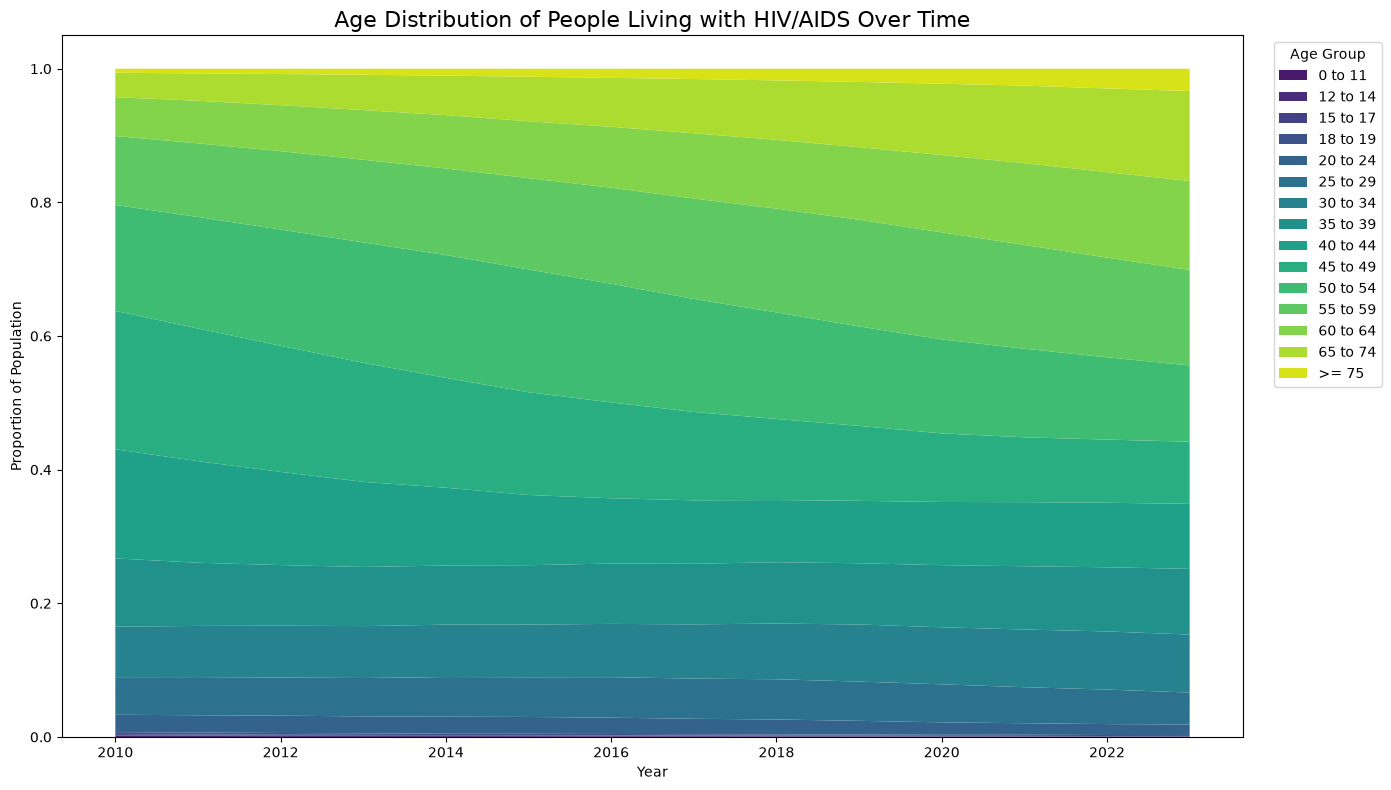

In [14]:
# Keep only age data
age_data = hiv_aids.xs("Age", level="Category")

# Convert to wide format
pivot = age_data["Count_Living"].unstack("Group").fillna(0)

# Convert each year to proportions
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0)


fig, ax = plt.subplots(figsize=(14, 8))


ax.stackplot(
    pivot_pct.index,
    pivot_pct.T,
    labels=pivot_pct.columns,
    colors=sns.color_palette("viridis", len(pivot_pct.columns))
)


ax.set_title(
    "Age Distribution of People Living with HIV/AIDS Over Time",
    fontsize=16
)


ax.set_xlabel("Year")
ax.set_ylabel("Proportion of Population")


ax.legend(
    title="Age Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


plt.tight_layout()
plt.show()